In [392]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [393]:
data = pd.read_csv("COVID-19_Reported_Patient_Impact_and_Hospital_Capacity_by_State.csv")
df = data.copy()

C:\Users\Rafi\AppData\Local\Temp\ipykernel_19540\2487329142.py:1: DtypeWarning: Columns (0: hospital_onset_covid, 1: previous_day_admission_adult_covid_confirmed, 2: previous_day_admission_adult_covid_suspected, 3: previous_day_admission_pediatric_covid_suspected, 4: staffed_icu_adult_patients_confirmed_and_suspected_covid, 5: staffed_icu_adult_patients_confirmed_covid, 6: total_pediatric_patients_hospitalized_confirmed_and_suspected_covid, 7: adult_icu_bed_covid_utilization_numerator, 8: deaths_covid, 9: on_hand_supply_therapeutic_a_casirivimab_imdevimab_courses, 10: on_hand_supply_therapeutic_b_bamlanivimab_courses, 11: on_hand_supply_therapeutic_c_bamlanivimab_etesevimab_courses, 12: previous_week_therapeutic_a_casirivimab_imdevimab_courses_used, 13: previous_week_therapeutic_b_bamlanivimab_courses_used, 14: previous_week_therapeutic_c_bamlanivimab_etesevimab_courses_used, 15: total_patients_hospitalized_confirmed_influenza) have mixed types. Specify dtype option on import or set lo

In [394]:
df.head()

,state,date,critical_staffing_shortage_today_yes,critical_staffing_shortage_today_no,critical_staffing_shortage_today_not_reported,critical_staffing_shortage_anticipated_within_week_yes,critical_staffing_shortage_anticipated_within_week_no,critical_staffing_shortage_anticipated_within_week_not_reported,hospital_onset_covid,hospital_onset_covid_coverage,...,previous_day_admission_pediatric_covid_confirmed_5_11,previous_day_admission_pediatric_covid_confirmed_5_11_coverage,previous_day_admission_pediatric_covid_confirmed_unknown,previous_day_admission_pediatric_covid_confirmed_unknown_coverage,staffed_icu_pediatric_patients_confirmed_covid,staffed_icu_pediatric_patients_confirmed_covid_coverage,staffed_pediatric_icu_bed_occupancy,staffed_pediatric_icu_bed_occupancy_coverage,total_staffed_pediatric_icu_beds,total_staffed_pediatric_icu_beds_coverage
0,MN,2021 Jun 19 12:00:00 AM,13,111,15,13,111,15,2.0,138,...,NaN,0,NaN,0,NaN,0,403,138,501,138
1,ID,2020 Oct 13 12:00:00 AM,1,46,3,2,45,3,3.0,47,...,NaN,0,NaN,0,1.0,47,60,46,208,46
2,DC,2020 Aug 27 12:00:00 AM,2,10,2,2,10,2,1.0,13,...,NaN,0,NaN,0,0.0,11,170,11,220,11
3,IA,2021 Jun 16 12:00:00 AM,0,57,69,1,55,70,0.0,124,...,NaN,0,NaN,0,NaN,0,NaN,0,NaN,0
4,KS,2021 Jun 13 12:00:00 AM,10,137,3,15,132,3,1.0,147,...,NaN,0,NaN,0,NaN,0,77,147,279,147


In [395]:
df.tail()

,state,date,critical_staffing_shortage_today_yes,critical_staffing_shortage_today_no,critical_staffing_shortage_today_not_reported,critical_staffing_shortage_anticipated_within_week_yes,critical_staffing_shortage_anticipated_within_week_no,critical_staffing_shortage_anticipated_within_week_not_reported,hospital_onset_covid,hospital_onset_covid_coverage,...,previous_day_admission_pediatric_covid_confirmed_5_11,previous_day_admission_pediatric_covid_confirmed_5_11_coverage,previous_day_admission_pediatric_covid_confirmed_unknown,previous_day_admission_pediatric_covid_confirmed_unknown_coverage,staffed_icu_pediatric_patients_confirmed_covid,staffed_icu_pediatric_patients_confirmed_covid_coverage,staffed_pediatric_icu_bed_occupancy,staffed_pediatric_icu_bed_occupancy_coverage,total_staffed_pediatric_icu_beds,total_staffed_pediatric_icu_beds_coverage
81330,NE,2023 Jul 04 12:00:00 AM,0,8,87,4,79,12,0.0,39,...,0.0,87,0.0,94,0.0,94,79,94,95,94
81331,IL,2023 Jun 14 12:00:00 AM,3,48,134,3,149,33,7.0,75,...,0.0,165,0.0,178,0.0,180,368,180,578,180
81332,NM,2023 Aug 23 12:00:00 AM,0,3,45,15,30,3,0.0,3,...,0.0,42,0.0,47,0.0,46,25,46,40,46
81333,WA,2023 Jul 21 12:00:00 AM,0,2,92,0,3,91,0.0,90,...,0.0,92,0.0,92,1.0,92,58,92,88,91
81334,WV,2023 May 21 12:00:00 AM,0,3,52,21,30,4,0.0,51,...,0.0,51,0.0,4,0.0,51,22,51,44,51


In [396]:
df.shape

(81335, 135)

In [397]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 81335 entries, 0 to 81334
Columns: 135 entries, state to total_staffed_pediatric_icu_beds_coverage
dtypes: float64(41), int64(56), object(13), str(25)
memory usage: 83.8+ MB


In [398]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
critical_staffing_shortage_today_yes,81335.0,7.883826,14.950133,0.0,0.0,2.0,10.0,191.0
critical_staffing_shortage_today_no,81335.0,47.540321,59.096154,0.0,3.0,24.0,78.0,494.0
critical_staffing_shortage_today_not_reported,81335.0,47.322887,69.301378,0.0,5.0,22.0,64.0,523.0
critical_staffing_shortage_anticipated_within_week_yes,81335.0,12.675933,18.946847,0.0,1.0,6.0,18.0,204.0
critical_staffing_shortage_anticipated_within_week_no,81335.0,62.465544,59.428789,0.0,17.0,52.0,90.0,469.0
...,...,...,...,...,...,...,...,...
previous_day_admission_pediatric_covid_confirmed_unknown_coverage,81335.0,52.762304,79.476808,0.0,0.0,13.0,93.0,595.0
staffed_icu_pediatric_patients_confirmed_covid,51186.0,2.624858,5.815016,0.0,0.0,1.0,3.0,346.0
staffed_icu_pediatric_patients_confirmed_covid_coverage,81335.0,57.492605,80.026526,0.0,0.0,26.0,95.0,595.0
staffed_pediatric_icu_bed_occupancy_coverage,81335.0,78.814975,85.624623,0.0,15.0,59.0,112.0,597.0


In [399]:
df.count()

state                                                      81335
date                                                       81335
critical_staffing_shortage_today_yes                       81335
critical_staffing_shortage_today_no                        81335
critical_staffing_shortage_today_not_reported              81335
                                                           ...  
staffed_icu_pediatric_patients_confirmed_covid_coverage    81335
staffed_pediatric_icu_bed_occupancy                        73032
staffed_pediatric_icu_bed_occupancy_coverage               81335
total_staffed_pediatric_icu_beds                           73019
total_staffed_pediatric_icu_beds_coverage                  81335
Length: 135, dtype: int64

In [400]:
df.dtypes

state                                                        str
date                                                         str
critical_staffing_shortage_today_yes                       int64
critical_staffing_shortage_today_no                        int64
critical_staffing_shortage_today_not_reported              int64
                                                           ...  
staffed_icu_pediatric_patients_confirmed_covid_coverage    int64
staffed_pediatric_icu_bed_occupancy                          str
staffed_pediatric_icu_bed_occupancy_coverage               int64
total_staffed_pediatric_icu_beds                             str
total_staffed_pediatric_icu_beds_coverage                  int64
Length: 135, dtype: object

In [401]:
df.columns

Index(['state', 'date', 'critical_staffing_shortage_today_yes',
       'critical_staffing_shortage_today_no',
       'critical_staffing_shortage_today_not_reported',
       'critical_staffing_shortage_anticipated_within_week_yes',
       'critical_staffing_shortage_anticipated_within_week_no',
       'critical_staffing_shortage_anticipated_within_week_not_reported',
       'hospital_onset_covid', 'hospital_onset_covid_coverage',
       ...
       'previous_day_admission_pediatric_covid_confirmed_5_11',
       'previous_day_admission_pediatric_covid_confirmed_5_11_coverage',
       'previous_day_admission_pediatric_covid_confirmed_unknown',
       'previous_day_admission_pediatric_covid_confirmed_unknown_coverage',
       'staffed_icu_pediatric_patients_confirmed_covid',
       'staffed_icu_pediatric_patients_confirmed_covid_coverage',
       'staffed_pediatric_icu_bed_occupancy',
       'staffed_pediatric_icu_bed_occupancy_coverage',
       'total_staffed_pediatric_icu_beds',
       't

In [402]:
df.nunique()

state                                                        54
date                                                       1572
critical_staffing_shortage_today_yes                        186
critical_staffing_shortage_today_no                         444
critical_staffing_shortage_today_not_reported               430
                                                           ... 
staffed_icu_pediatric_patients_confirmed_covid_coverage     381
staffed_pediatric_icu_bed_occupancy                        1584
staffed_pediatric_icu_bed_occupancy_coverage                410
total_staffed_pediatric_icu_beds                           1873
total_staffed_pediatric_icu_beds_coverage                   406
Length: 135, dtype: int64

In [403]:
df["state"].value_counts(normalize=True) * 100

state
MN    1.932747
HI    1.932747
MT    1.932747
AL    1.932747
NC    1.932747
IN    1.932747
TX    1.932747
NV    1.910617
KS    1.894633
IL    1.873732
MS    1.872503
WV    1.871273
MO    1.867585
OR    1.866355
PR    1.865126
LA    1.865126
CA    1.865126
WA    1.861437
IA    1.858978
ME    1.858978
NE    1.858978
PA    1.858978
ND    1.858978
OH    1.858978
KY    1.858978
WI    1.858978
GA    1.858978
WY    1.858978
MI    1.858978
OK    1.858978
MD    1.858978
NJ    1.858978
AZ    1.857749
SC    1.857749
VA    1.857749
RI    1.856519
AR    1.852831
FL    1.845454
ID    1.844225
NY    1.842995
CO    1.842995
TN    1.842995
NM    1.842995
VT    1.839307
CT    1.838077
UT    1.835618
AK    1.831930
SD    1.829471
MA    1.827012
DE    1.827012
NH    1.827012
DC    1.825782
VI    1.812258
AS    1.193828
Name: proportion, dtype: float64

In [404]:
df["state"].unique()

<StringArray>
['MN', 'ID', 'DC', 'IA', 'KS', 'MA', 'HI', 'MT', 'AK', 'ME', 'NE', 'PR', 'NY',
 'SD', 'RI', 'MS', 'LA', 'CO', 'PA', 'AZ', 'ND', 'OH', 'AL', 'DE', 'NH', 'KY',
 'WI', 'TN', 'AR', 'OR', 'WA', 'UT', 'GA', 'NV', 'SC', 'VA', 'NM', 'WY', 'MI',
 'WV', 'CA', 'NC', 'IN', 'CT', 'VT', 'IL', 'TX', 'VI', 'FL', 'OK', 'MD', 'NJ',
 'AS', 'MO']
Length: 54, dtype: str

In [405]:
df[["date", "state", "adult_icu_bed_utilization"]].head()

,date,state,adult_icu_bed_utilization
0,2021 Jun 19 12:00:00 AM,MN,0.648709
1,2020 Oct 13 12:00:00 AM,ID,0.700000
2,2020 Aug 27 12:00:00 AM,DC,0.716667
3,2021 Jun 16 12:00:00 AM,IA,0.668666
4,2021 Jun 13 12:00:00 AM,KS,0.638298


In [406]:
#data cleaning
df.isna().sum().sort_values(ascending=False).head(10)

geocoded_state                                                      81335
previous_day_admission_pediatric_covid_confirmed_12_17              37042
previous_day_admission_pediatric_covid_confirmed_5_11               37029
previous_day_admission_pediatric_covid_confirmed_0_4                36412
previous_day_admission_pediatric_covid_confirmed_unknown            36296
staffed_icu_pediatric_patients_confirmed_covid                      30149
on_hand_supply_therapeutic_c_bamlanivimab_etesevimab_courses        22816
previous_week_therapeutic_c_bamlanivimab_etesevimab_courses_used    22760
on_hand_supply_therapeutic_b_bamlanivimab_courses                   20213
previous_week_therapeutic_b_bamlanivimab_courses_used               20141
dtype: int64

In [407]:
df.duplicated().sum()

np.int64(0)

In [408]:
df.duplicated(subset=["date", "state"]).sum()

np.int64(0)

In [409]:
df["state"] = df["state"].str.upper().str.strip()

In [410]:
df["state"].unique()

<StringArray>
['MN', 'ID', 'DC', 'IA', 'KS', 'MA', 'HI', 'MT', 'AK', 'ME', 'NE', 'PR', 'NY',
 'SD', 'RI', 'MS', 'LA', 'CO', 'PA', 'AZ', 'ND', 'OH', 'AL', 'DE', 'NH', 'KY',
 'WI', 'TN', 'AR', 'OR', 'WA', 'UT', 'GA', 'NV', 'SC', 'VA', 'NM', 'WY', 'MI',
 'WV', 'CA', 'NC', 'IN', 'CT', 'VT', 'IL', 'TX', 'VI', 'FL', 'OK', 'MD', 'NJ',
 'AS', 'MO']
Length: 54, dtype: str

In [411]:
df["date"].isna().sum()

np.int64(0)

In [412]:
df['date'] = pd.to_datetime(df['date'])

C:\Users\Rafi\AppData\Local\Temp\ipykernel_19540\3532345252.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'])


In [413]:
df["date"].dtype

dtype('<M8[us]')

In [414]:
df["date"].head()
df["date"].tail()

81330   2023-07-04
81331   2023-06-14
81332   2023-08-23
81333   2023-07-21
81334   2023-05-21
Name: date, dtype: datetime64[us]

In [415]:
df["adult_icu_bed_utilization"].isna().sum()

np.int64(7485)

In [416]:
df=df.dropna(subset=["adult_icu_bed_utilization"])

In [417]:
df["adult_icu_bed_utilization"].isna().sum()

np.int64(0)

In [418]:
df["adult_icu_bed_utilization"].describe()

count    73850.000000
mean         0.704251
std          0.115650
min          0.000000
25%          0.652823
50%          0.721432
75%          0.781488
max          1.166667
Name: adult_icu_bed_utilization, dtype: float64

In [419]:
df["total_staffed_adult_icu_beds"].isna().sum()

np.int64(0)

In [420]:
df["total_staffed_adult_icu_beds"] = df["total_staffed_adult_icu_beds"].astype(str).str.replace(",", "").astype(int)


In [421]:
df["total_staffed_adult_icu_beds"]=df["total_staffed_adult_icu_beds"].fillna(df["total_staffed_adult_icu_beds"].median())

In [422]:
df["total_staffed_adult_icu_beds"].isna().sum()

np.int64(0)

In [423]:
df["inpatient_beds"].isna().sum()

np.int64(0)

In [424]:
df["inpatient_beds"] = df["inpatient_beds"].astype(str).str.replace(",", "").astype(int)


In [425]:
df["inpatient_beds_used"].isna().sum()

np.int64(0)

In [426]:
df["inpatient_beds_used_covid"].isna().sum()

np.int64(732)

In [427]:
df["inpatient_beds_used_covid"] = df["inpatient_beds_used_covid"].astype(str).str.replace(",", "").astype(float)


In [428]:
df["inpatient_beds_used_covid"]=df["inpatient_beds_used_covid"].fillna(df["inpatient_beds_used_covid"].median())

In [429]:
df["inpatient_beds_used_covid"].isna().sum()

np.int64(0)

In [430]:
df["staffed_icu_adult_patients_confirmed_covid"].isna().sum()

np.int64(0)

In [431]:
df["staffed_icu_adult_patients_confirmed_covid"] = df["staffed_icu_adult_patients_confirmed_covid"].astype(str).str.replace(",", "").astype(int)

In [432]:
df["staffed_icu_adult_patients_confirmed_covid"].value_counts(dropna=False)

staffed_icu_adult_patients_confirmed_covid
0       2635
1       1592
3       1547
2       1533
4       1527
        ... 
1964       1
2105       1
1919       1
2477       1
2588       1
Name: count, Length: 1913, dtype: int64

In [433]:
df["staffed_icu_adult_patients_confirmed_covid"]=df["staffed_icu_adult_patients_confirmed_covid"].fillna(df["staffed_icu_adult_patients_confirmed_covid"].median())

In [434]:
df["previous_day_admission_adult_covid_confirmed"].isna().sum()

np.int64(0)

In [435]:
df["previous_day_admission_adult_covid_confirmed"] = df["previous_day_admission_adult_covid_confirmed"].astype(str).str.replace(",", "").astype(int)

In [436]:
df["critical_staffing_shortage_today_yes"].isna().sum()

np.int64(0)

In [437]:
df["critical_staffing_shortage_today_yes"] = df["critical_staffing_shortage_today_yes"].astype(str).str.replace(",", "").astype(int)

In [438]:
cols = ["inpatient_beds_used_covid","critical_staffing_shortage_today_yes","previous_day_admission_adult_covid_confirmed","staffed_icu_adult_patients_confirmed_covid", "total_staffed_adult_icu_beds", "inpatient_beds", "adult_icu_bed_utilization"]

In [439]:
print(df[cols].dtypes)

inpatient_beds_used_covid                       float64
critical_staffing_shortage_today_yes              int64
previous_day_admission_adult_covid_confirmed      int64
staffed_icu_adult_patients_confirmed_covid        int64
total_staffed_adult_icu_beds                      int64
inpatient_beds                                    int64
adult_icu_bed_utilization                       float64
dtype: object


In [440]:
df[df.isna().any(axis=1)].head()

,state,date,critical_staffing_shortage_today_yes,critical_staffing_shortage_today_no,critical_staffing_shortage_today_not_reported,critical_staffing_shortage_anticipated_within_week_yes,critical_staffing_shortage_anticipated_within_week_no,critical_staffing_shortage_anticipated_within_week_not_reported,hospital_onset_covid,hospital_onset_covid_coverage,...,previous_day_admission_pediatric_covid_confirmed_5_11,previous_day_admission_pediatric_covid_confirmed_5_11_coverage,previous_day_admission_pediatric_covid_confirmed_unknown,previous_day_admission_pediatric_covid_confirmed_unknown_coverage,staffed_icu_pediatric_patients_confirmed_covid,staffed_icu_pediatric_patients_confirmed_covid_coverage,staffed_pediatric_icu_bed_occupancy,staffed_pediatric_icu_bed_occupancy_coverage,total_staffed_pediatric_icu_beds,total_staffed_pediatric_icu_beds_coverage
0,MN,2021-06-19,13,111,15,13,111,15,2.0,138,...,NaN,0,NaN,0,NaN,0,403,138,501,138
1,ID,2020-10-13,1,46,3,2,45,3,3.0,47,...,NaN,0,NaN,0,1.0,47,60,46,208,46
2,DC,2020-08-27,2,10,2,2,10,2,1.0,13,...,NaN,0,NaN,0,0.0,11,170,11,220,11
3,IA,2021-06-16,0,57,69,1,55,70,0.0,124,...,NaN,0,NaN,0,NaN,0,NaN,0,NaN,0
4,KS,2021-06-13,10,137,3,15,132,3,1.0,147,...,NaN,0,NaN,0,NaN,0,77,147,279,147


In [441]:
df = df.sort_values(by="date")

In [442]:
df[["date", "state", "adult_icu_bed_utilization"]].head()

,date,state,adult_icu_bed_utilization
27093,2020-01-02,NV,0.849391
31577,2020-01-03,NV,0.849391
26241,2020-01-04,AR,0.166667
30871,2020-01-04,NV,0.849391
33109,2020-01-05,NV,0.849391


In [443]:
#Check Outliers + Treatment

In [444]:
df["adult_icu_bed_utilization"].describe()

count    73850.000000
mean         0.704251
std          0.115650
min          0.000000
25%          0.652823
50%          0.721432
75%          0.781488
max          1.166667
Name: adult_icu_bed_utilization, dtype: float64

In [445]:
df["adult_icu_bed_utilization"].value_counts().head()

adult_icu_bed_utilization
0.714286    336
0.571429    335
0.500000    297
0.428571    280
0.857143    179
Name: count, dtype: int64

In [446]:
df[df["adult_icu_bed_utilization"] < 0]

,state,date,critical_staffing_shortage_today_yes,critical_staffing_shortage_today_no,critical_staffing_shortage_today_not_reported,critical_staffing_shortage_anticipated_within_week_yes,critical_staffing_shortage_anticipated_within_week_no,critical_staffing_shortage_anticipated_within_week_not_reported,hospital_onset_covid,hospital_onset_covid_coverage,...,previous_day_admission_pediatric_covid_confirmed_5_11,previous_day_admission_pediatric_covid_confirmed_5_11_coverage,previous_day_admission_pediatric_covid_confirmed_unknown,previous_day_admission_pediatric_covid_confirmed_unknown_coverage,staffed_icu_pediatric_patients_confirmed_covid,staffed_icu_pediatric_patients_confirmed_covid_coverage,staffed_pediatric_icu_bed_occupancy,staffed_pediatric_icu_bed_occupancy_coverage,total_staffed_pediatric_icu_beds,total_staffed_pediatric_icu_beds_coverage


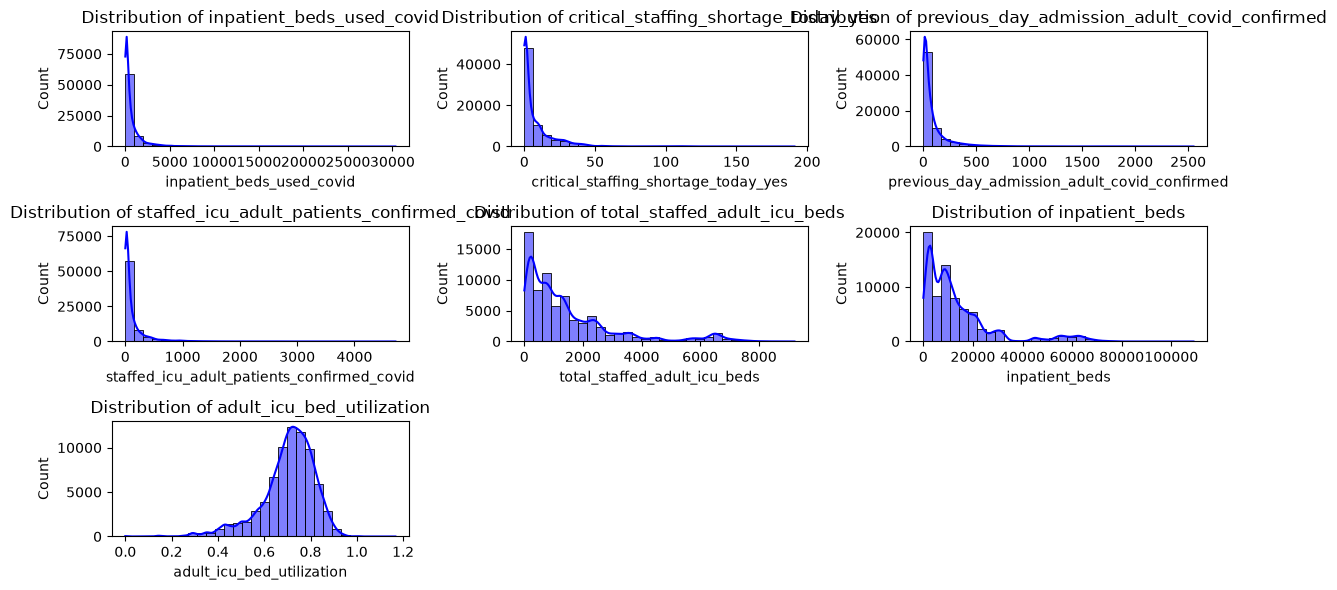

In [447]:
cols = [
    "inpatient_beds_used_covid",
    "critical_staffing_shortage_today_yes",
    "previous_day_admission_adult_covid_confirmed",
    "staffed_icu_adult_patients_confirmed_covid",
    "total_staffed_adult_icu_beds",
    "inpatient_beds",
    "adult_icu_bed_utilization"
]
plt.figure(figsize=(12, 6))
for i, feature in enumerate(cols):
    plt.subplot(3, 3, i + 1)
    sns.histplot(df[feature], kde=True, bins=30, color="blue")
    plt.title(f"Distribution of {feature}")
plt.tight_layout()
plt.show()


In [448]:
outliers_beds[["date", "state", "total_staffed_adult_icu_beds"]].head()

,date,state,total_staffed_adult_icu_beds
18747,2020-07-22,FL,4911
19896,2020-07-23,FL,5523
22405,2020-07-23,CA,6581
17584,2020-07-23,TX,6169
16237,2020-07-24,TX,4493


In [449]:
outliers_numerator[["date", "state", "adult_icu_bed_utilization_numerator"]].head()

,date,state,adult_icu_bed_utilization_numerator
18096,2020-07-17,TX,3016.0
12741,2020-07-18,TX,3037.0
19332,2020-07-19,TX,2983.0
21452,2020-07-20,TX,2999.0
19437,2020-07-21,TX,3099.0


In [450]:
outliers_denominator[["date", "state", "adult_icu_bed_utilization_denominator"]].head(10)

,date,state,adult_icu_bed_utilization_denominator
18747,2020-07-22,FL,4911.0
22405,2020-07-23,CA,6581.0
17584,2020-07-23,TX,6169.0
19896,2020-07-23,FL,5523.0
20090,2020-07-24,CA,6264.0
16237,2020-07-24,TX,4493.0
14168,2020-07-24,FL,5713.0
19189,2020-07-25,FL,5772.0
18725,2020-07-25,TX,5923.0
18848,2020-07-25,CA,7036.0


In [451]:
df_clean = df.copy()

In [452]:
#Bivariate Analysis

In [453]:
df_clean.groupby("state")["adult_icu_bed_utilization"].mean().sort_values(ascending=False).head(10)

state
TX    0.864990
RI    0.828598
AL    0.828459
NC    0.802616
NM    0.800790
GA    0.799629
MO    0.780490
MS    0.777921
DC    0.777816
MI    0.773607
Name: adult_icu_bed_utilization, dtype: float64

In [454]:
df_clean.groupby("state")["date"].agg(["min", "max", "count"])

,min,max,count
state,,,
AK,2020-07-15,2024-04-20,1376
AL,2020-07-15,2024-04-20,1370
AR,2020-01-04,2024-04-20,1381
AS,2021-08-24,2024-04-20,971
AZ,2020-07-15,2024-04-20,1376
CA,2020-07-15,2024-04-20,1376
CO,2020-07-15,2024-04-20,1376
CT,2020-07-15,2024-04-20,1371
DC,2020-07-16,2024-04-20,1375
